In [ ]:
!pip install "numpy<2.0" "pandas<2.2" "matplotlib<3.8" --force-reinstall
!pip install -q vit-keras
!pip install -q tfswin

# Imports & Setup

In [3]:
import os
import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers
from tensorflow.keras import backend as K
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tfswin import SwinTransformerTiny224

# --- ENSURE REPRODUCIBILITY ---
SEED = 42
def set_global_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    print(f"Global Seed set to: {seed}")

set_global_seed(SEED)

# --- SINGLE GPU SETUP ---
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.set_visible_devices(gpus[0], 'GPU')
        print(f"Running on Single GPU: {gpus[0].name}")
    except RuntimeError as e:
        print(e)
else:
    print("Running on CPU")

Global Seed set to: 42
Running on Single GPU: /physical_device:GPU:0


# Data Loading

In [4]:
# --- DATA LOADING ---
DATA_DIR = '/kaggle/input/quickdraw20/quickdraw_data'
# Loading 50 categories as requested
categories = [f.split('.')[0] for f in os.listdir(DATA_DIR) if f.endswith('.npy')]
categories = categories[:50] 

X_data = []
y_data = []
MAX_IMAGES = 2000 

print(f"Loading Data for {len(categories)} categories...")
for idx, cat in enumerate(categories):
    try:
        file_path = os.path.join(DATA_DIR, f"{cat}.npy")
        data = np.load(file_path)
        data = data[:MAX_IMAGES]
        X_data.append(data)
        y_data.append(np.full(data.shape[0], idx))
    except Exception as e:
        print(f"Error loading {cat}: {e}")

X = np.concatenate(X_data, axis=0)
y = np.concatenate(y_data, axis=0)

# Normalize and Reshape
X = X.reshape(-1, 28, 28, 1).astype('float32') / 255.0
y = to_categorical(y, num_classes=len(categories))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Data Ready. Train shape: {X_train.shape}")

Loading Data for 50 categories...
Data Ready. Train shape: (80000, 28, 28, 1)


# Model Architectures

In [6]:
# --- MODEL BUILDERS ---

def cbam_block(input_feature):
    # Fixed Spatial Attention with Lambda wrappers
    avg_pool = layers.Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True), name='att_avg_pool')(input_feature)
    max_pool = layers.Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True), name='att_max_pool')(input_feature)
    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])
    cbam_feature = layers.Conv2D(1, (7, 7), padding='same', activation='sigmoid', kernel_initializer='he_normal')(concat)
    return layers.Multiply()([input_feature, cbam_feature])

def get_model(model_name, num_classes):
    inputs = layers.Input(shape=(28, 28, 1))
    
    if model_name == 'SwinTiny':
        target_size = 224
    else:
        target_size = 128 
        
    x = layers.Resizing(target_size, target_size)(inputs)
    x = layers.Conv2D(3, (3, 3), padding='same')(x) 

    if model_name == 'ResNet50':
        backbone = applications.ResNet50(include_top=False, weights='imagenet', input_shape=(target_size, target_size, 3))
        x = backbone(x)
        x = layers.GlobalAveragePooling2D()(x)
        
    elif model_name == 'EfficientNetB0':
        backbone = applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(target_size, target_size, 3))
        x = backbone(x)
        x = layers.GlobalAveragePooling2D()(x)
        
    elif model_name == 'MobileNetV3':
        backbone = applications.MobileNetV3Small(include_top=False, weights='imagenet', input_shape=(target_size, target_size, 3))
        x = backbone(x)
        x = layers.GlobalAveragePooling2D()(x)
    
    elif model_name == 'SwinTiny':
        backbone = SwinTransformerTiny224(include_top=False, weights='imagenet')
        x = backbone(x)
        x = layers.GlobalAveragePooling2D()(x)
        
    elif model_name == 'Attention_MobileNetV3':
        backbone = applications.MobileNetV3Small(include_top=False, weights='imagenet', input_shape=(target_size, target_size, 3))
        features = backbone(x)
        x = cbam_block(features)
        x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs, name=model_name)
    return model

# Initialize Logging

In [7]:
# Initialize dictionaries to store results from subsequent cells
history_dict = {}
evaluation_results = []
EPOCHS = 7
print("Logging initialized. You can now run the model cells below.")

Logging initialized. You can now run the model cells below.


# Train MobileNetV3

In [8]:
name = 'MobileNetV3'
print(f"\n{'='*50}\nTRAINING: {name}\n{'='*50}")

K.clear_session()
gc.collect()

model = get_model(name, len(categories))
opt = optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

hist = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

model.save_weights(f"{name}.weights.h5")
history_dict[name] = hist.history
final_acc = hist.history['val_accuracy'][-1]
evaluation_results.append({'Model': name, 'Accuracy': final_acc})


TRAINING: MobileNetV3
Epoch 1/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 76s 31ms/step - accuracy: 0.3083 - loss: 2.7429 - val_accuracy: 0.0292 - val_loss: 4.3827
Epoch 2/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.6824 - loss: 1.1794 - val_accuracy: 0.0191 - val_loss: 4.9431
Epoch 3/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.7496 - loss: 0.9265 - val_accuracy: 0.0310 - val_loss: 5.2704
Epoch 4/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.7827 - loss: 0.7945 - val_accuracy: 0.2083 - val_loss: 3.0873
Epoch 5/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.8084 - loss: 0.6998 - val_accuracy: 0.5296 - val_loss: 1.7958
Epoch 6/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.8252 - loss: 0.6235 - val_accuracy: 0.5414 - val_loss: 1.7510
Epoch 7/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.8445 - loss: 0.5524 - val_accuracy: 0.6766 - val_loss: 1.2411


# Train Attention MobileNetV3

In [10]:
name = 'Attention_MobileNetV3'
print(f"\n{'='*50}\nTRAINING: {name}\n{'='*50}")

K.clear_session()
gc.collect()

model = get_model(name, len(categories))
opt = optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

hist = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

model.save_weights(f"{name}.weights.h5")
history_dict[name] = hist.history
final_acc = hist.history['val_accuracy'][-1]
evaluation_results.append({'Model': name, 'Accuracy': final_acc})


TRAINING: Attention_MobileNetV3
Epoch 1/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 76s 31ms/step - accuracy: 0.2833 - loss: 2.8559 - val_accuracy: 0.0209 - val_loss: 4.3260
Epoch 2/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.6607 - loss: 1.2492 - val_accuracy: 0.0305 - val_loss: 4.6789
Epoch 3/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.7351 - loss: 0.9695 - val_accuracy: 0.0196 - val_loss: 4.5360
Epoch 4/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.7690 - loss: 0.8277 - val_accuracy: 0.0198 - val_loss: 6.4120
Epoch 5/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.7958 - loss: 0.7251 - val_accuracy: 0.0197 - val_loss: 10.5970
Epoch 6/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.8186 - loss: 0.6456 - val_accuracy: 0.0215 - val_loss: 5.8614
Epoch 7/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.8339 - loss: 0.5800 - val_accuracy: 0.0219 - val_loss: 37.2155


# Train ResNet50

In [11]:
name = 'ResNet50'
print(f"\n{'='*50}\nTRAINING: {name}\n{'='*50}")

K.clear_session()
gc.collect()

model = get_model(name, len(categories))
opt = optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

hist = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

model.save_weights(f"{name}.weights.h5")
history_dict[name] = hist.history
final_acc = hist.history['val_accuracy'][-1]
evaluation_results.append({'Model': name, 'Accuracy': final_acc})


TRAINING: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/7


2025-12-26 16:56:50.333345: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 16:56:50.484539: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 330s 221ms/step - accuracy: 0.6051 - loss: 1.5743 - val_accuracy: 0.7164 - val_loss: 1.0375
Epoch 2/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 270s 216ms/step - accuracy: 0.8177 - loss: 0.6688 - val_accuracy: 0.8069 - val_loss: 0.7141
Epoch 3/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 269s 216ms/step - accuracy: 0.8670 - loss: 0.4665 - val_accuracy: 0.8024 - val_loss: 0.7605
Epoch 4/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 270s 216ms/step - accuracy: 0.8965 - loss: 0.3528 - val_accuracy: 0.7930 - val_loss: 0.8650
Epoch 5/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 269s 215ms/step - accuracy: 0.9168 - loss: 0.2767 - val_accuracy: 0.8077 - val_loss: 0.8504
Epoch 6/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 269s 215ms/step - accuracy: 0.9350 - loss: 0.2157 - val_accuracy: 0.8025 - val_loss: 0.9153
Epoch 7/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 269s 215ms/step - accuracy: 0.9451 - loss: 0.1745 - val_accuracy: 0.8047 - val_loss: 0.9771


# Train EfficientNetB0

In [12]:
name = 'EfficientNetB0'
print(f"\n{'='*50}\nTRAINING: {name}\n{'='*50}")

K.clear_session()
gc.collect()

model = get_model(name, len(categories))
opt = optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

hist = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

model.save_weights(f"{name}.weights.h5")
history_dict[name] = hist.history
final_acc = hist.history['val_accuracy'][-1]
evaluation_results.append({'Model': name, 'Accuracy': final_acc})


TRAINING: EfficientNetB0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/7


2025-12-26 17:29:37.202811: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:29:37.339367: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:29:37.659581: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:29:37.799713: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:29:38.510298: E external/local_xla/xla/stream_

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.4522 - loss: 2.2016

2025-12-26 17:32:04.997829: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:32:05.131680: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:32:05.438707: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:32:05.578758: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-26 17:32:06.295512: E external/local_xla/xla/stream_

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 195s 99ms/step - accuracy: 0.4524 - loss: 2.2010 - val_accuracy: 0.2020 - val_loss: 3.3128
Epoch 2/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 109s 87ms/step - accuracy: 0.7806 - loss: 0.8001 - val_accuracy: 0.2013 - val_loss: 3.3485
Epoch 3/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 108s 87ms/step - accuracy: 0.8282 - loss: 0.6174 - val_accuracy: 0.7542 - val_loss: 0.8918
Epoch 4/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 108s 86ms/step - accuracy: 0.8544 - loss: 0.5124 - val_accuracy: 0.1068 - val_loss: 3.6460
Epoch 5/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 108s 87ms/step - accuracy: 0.8774 - loss: 0.4200 - val_accuracy: 0.1875 - val_loss: 3.3214
Epoch 6/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 108s 86ms/step - accuracy: 0.8976 - loss: 0.3479 - val_accuracy: 0.0236 - val_loss: 4.0732
Epoch 7/7
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 108s 86ms/step - accuracy: 0.9128 - loss: 0.2909 - val_accuracy: 0.0953 - val_loss: 3.9346


# Train SwinTiny

In [13]:
name = 'SwinTiny'
print(f"\n{'='*50}\nTRAINING: {name}\n{'='*50}")

K.clear_session()
gc.collect()

model = get_model(name, len(categories))
# Using AdamW and smaller batch size for Swin
opt = optimizers.AdamW(learning_rate=5e-5, weight_decay=1e-4)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

hist = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

model.save_weights(f"{name}.weights.h5")
history_dict[name] = hist.history
final_acc = hist.history['val_accuracy'][-1]
evaluation_results.append({'Model': name, 'Accuracy': final_acc})


TRAINING: SwinTiny
177485300/177485300 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1756s 674ms/step - accuracy: 0.0194 - loss: 3.9274 - val_accuracy: 0.0188 - val_loss: 3.9121
Epoch 2/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1642s 657ms/step - accuracy: 0.0191 - loss: 3.9131 - val_accuracy: 0.0206 - val_loss: 3.9124
Epoch 3/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1627s 651ms/step - accuracy: 0.0191 - loss: 3.9128 - val_accuracy: 0.0195 - val_loss: 3.9121
Epoch 4/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1610s 644ms/step - accuracy: 0.0187 - loss: 3.9122 - val_accuracy: 0.0195 - val_loss: 3.9122
Epoch 5/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1610s 644ms/step - accuracy: 0.0200 - loss: 3.9123 - val_accuracy: 0.0182 - val_loss: 3.9122
Epoch 6/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1605s 642ms/step - accuracy: 0.0201 - loss: 3.9121 - val_accuracy: 0.0182 - val_loss: 3.9122
Epoch 7/7
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1603s 641ms/step - accuracy: 0.0203 - loss: 3.9121 - val_accuracy: 0.0182 - val_lo

# Visualization & Efficiency Plot

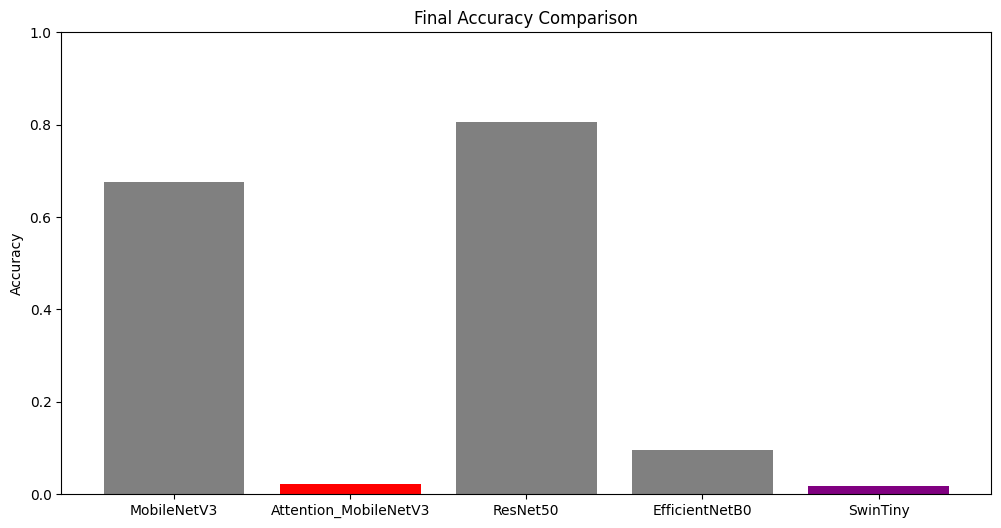


Calculating Efficiency metrics...


/usr/local/lib/python3.12/dist-packages/keras/src/applications/mobilenet_v3.py:452: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


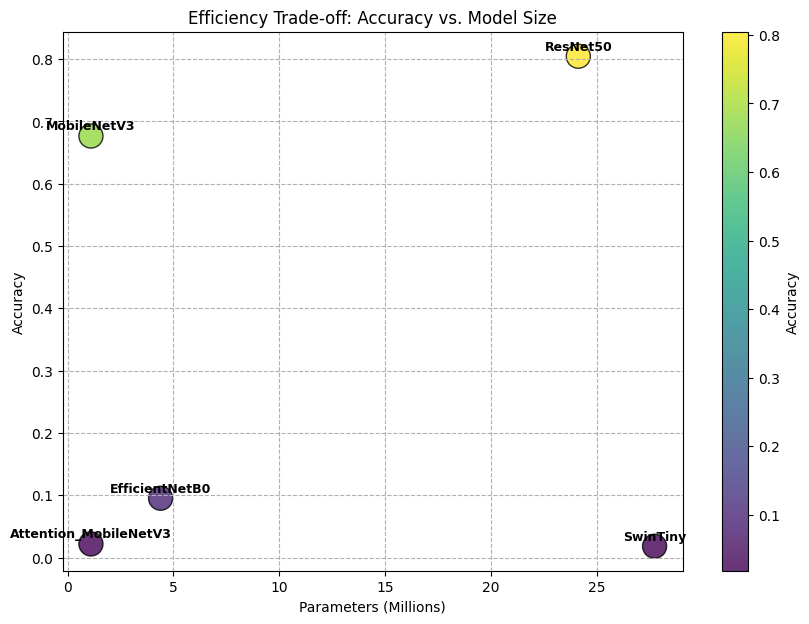


--- FINAL RESULTS TABLE ---
                Model  Accuracy  Params_Million
          MobileNetV3   0.67660        1.099712
Attention_MobileNetV3   0.02190        1.099811
             ResNet50   0.80470       24.125136
       EfficientNetB0   0.09525        4.390387
             SwinTiny   0.01825       27.729098


In [20]:
# --- STEP 5: VISUALIZATION ---
df_res = pd.DataFrame(evaluation_results)

# 1. Bar Chart
plt.figure(figsize=(12, 6))
# Colors: Highlight 'Attention_MobileNetV3' (Red) vs others (Gray) vs Swin (Purple)
colors = []
for m in df_res['Model']:
    if 'Attention' in m: colors.append('red')
    elif 'Swin' in m: colors.append('purple')
    else: colors.append('gray')

plt.bar(df_res['Model'], df_res['Accuracy'], color=colors)
plt.title("Final Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0.0, 1.0)
plt.show()

# 2. Efficiency Scatter Plot
print("\nCalculating Efficiency metrics...")
param_counts = []
MODELS_TO_TEST = df_res['Model'].tolist()

for name in MODELS_TO_TEST:
    K.clear_session()
    # Calculate params on CPU to avoid GPU OOM during check
    with tf.device('/CPU:0'):
        temp_model = get_model(name, len(categories))
        param_counts.append(temp_model.count_params())

df_res['Params_Million'] = np.array(param_counts) / 1_000_000

plt.figure(figsize=(10, 7))
sns_plot = plt.scatter(
    df_res['Params_Million'], 
    df_res['Accuracy'], 
    s=300, 
    c=df_res['Accuracy'], 
    cmap='viridis', 
    edgecolor='black',
    alpha=0.8
)

for i, row in df_res.iterrows():
    plt.text(row['Params_Million'], row['Accuracy']+0.01, row['Model'], fontsize=9, fontweight='bold', ha='center')

plt.title("Efficiency Trade-off: Accuracy vs. Model Size")
plt.xlabel("Parameters (Millions)")
plt.ylabel("Accuracy")
plt.grid(True, linestyle='--')
plt.colorbar(sns_plot, label='Accuracy')
plt.show()

# Print the table to confirm
print("\n--- FINAL RESULTS TABLE ---")
print(df_res.to_string(index=False))

Reloading models for analysis...
Models reloaded and compiled successfully.

--- VISUAL EVIDENCE: ATTENTION MAPS ---


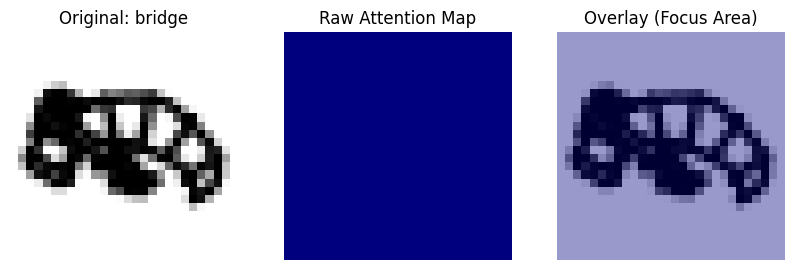

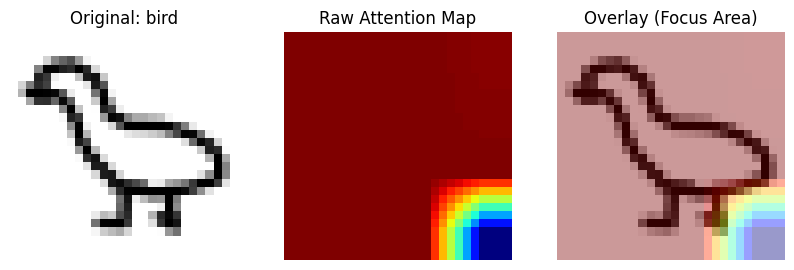

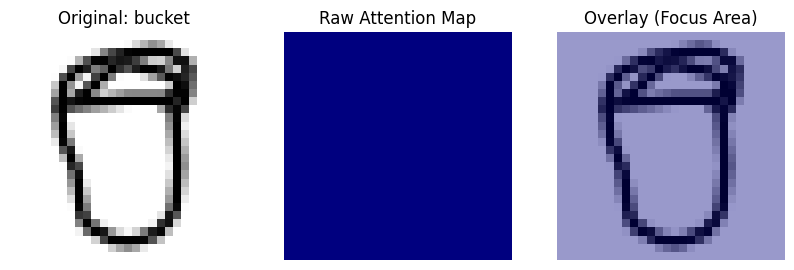


--- ROBUSTNESS TEST: MISSING STROKES ---
Vanilla MobileNet Accuracy on Broken Data:   0.0401
Attention MobileNet Accuracy on Broken Data: 0.0157


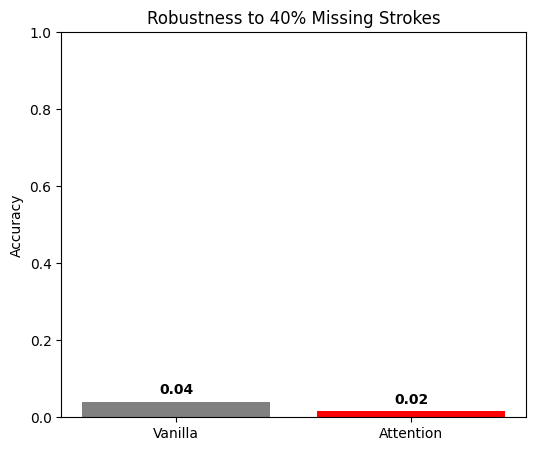

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import models, layers

# --- SETUP: RELOAD THE CRITICAL MODELS ---
print("Reloading models for analysis...")

# 1. Reload Vanilla MobileNet
model_vanilla = get_model('MobileNetV3', len(categories))
model_vanilla.load_weights('MobileNetV3.weights.h5')
# FIX: Compile it so it knows how to calculate accuracy
model_vanilla.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 2. Reload Attention MobileNet
model_attention = get_model('Attention_MobileNetV3', len(categories))
model_attention.load_weights('Attention_MobileNetV3.weights.h5')
# FIX: Compile it
model_attention.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Models reloaded and compiled successfully.")

# ==========================================
# PHASE 2: VISUAL EXPLAINABILITY (ATTENTION MAP)
# ==========================================

def visualize_cbam_attention(model, x_sample, category_name):
    """
    Extracts the spatial attention map from the Attention_MobileNetV3.
    """
    # 1. Find the Attention Layer (7x7 Conv with 1 filter)
    target_output = None
    for layer in model.layers:
        if isinstance(layer, layers.Conv2D) and layer.filters == 1 and layer.kernel_size == (7,7):
            target_output = layer.output
            break
            
    if target_output is None:
        print("Error: Could not find Attention Layer.")
        return

    # Build visualizer model
    vis_model = models.Model(model.input, target_output)
    
    # Predict map
    img_tensor = np.expand_dims(x_sample, axis=0)
    att_map = vis_model.predict(img_tensor, verbose=0)[0]
    
    # Process for display
    att_map = cv2.resize(att_map, (28, 28))
    # Normalize to 0-1 for clear visualization
    att_map = (att_map - att_map.min()) / (att_map.max() - att_map.min() + 1e-8)
    
    # Plotting
    plt.figure(figsize=(10, 4))
    
    # Original Sketch
    plt.subplot(1, 3, 1)
    plt.imshow(x_sample.reshape(28, 28), cmap='gray_r')
    plt.title(f"Original: {category_name}")
    plt.axis('off')
    
    # Attention Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(att_map, cmap='jet')
    plt.title("Raw Attention Map")
    plt.axis('off')
    
    # Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(x_sample.reshape(28, 28), cmap='gray_r', alpha=1.0)
    plt.imshow(att_map, cmap='jet', alpha=0.4) # Overlay
    plt.title("Overlay (Focus Area)")
    plt.axis('off')
    
    plt.show()

print("\n--- VISUAL EVIDENCE: ATTENTION MAPS ---")
# Pick a few random samples from Test set
indices = np.random.choice(len(X_test), 3)
for idx in indices:
    true_label = categories[np.argmax(y_test[idx])]
    visualize_cbam_attention(model_attention, X_test[idx], true_label)


# ==========================================
# PHASE 3: ROBUSTNESS STRESS TEST
# ==========================================

def create_broken_dataset(X, drop_prob=0.3):
    """Simulates 'Bad Drawings' by dropping strokes"""
    # Create a mask where drop_prob% of pixels are zeroed out
    mask = np.random.choice([0.0, 1.0], size=X.shape, p=[drop_prob, 1-drop_prob])
    return X * mask

print("\n--- ROBUSTNESS TEST: MISSING STROKES ---")
# Create broken data (40% missing)
X_test_broken = create_broken_dataset(X_test, drop_prob=0.4)

# Evaluate Both (Now works because we compiled them above)
loss_v, acc_v = model_vanilla.evaluate(X_test_broken, y_test, verbose=0)
loss_a, acc_a = model_attention.evaluate(X_test_broken, y_test, verbose=0)

print(f"Vanilla MobileNet Accuracy on Broken Data:   {acc_v:.4f}")
print(f"Attention MobileNet Accuracy on Broken Data: {acc_a:.4f}")

# Bar Chart
plt.figure(figsize=(6, 5))
plt.bar(['Vanilla', 'Attention'], [acc_v, acc_a], color=['gray', 'red'])
plt.title("Robustness to 40% Missing Strokes")
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
for i, v in enumerate([acc_v, acc_a]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')
plt.show()